In [62]:
# Imports
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from joblib import load, dump
import os
import tables
import pathlib
from IPython.display import display


from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from scipy.stats import pearsonr

### Datasets

In [37]:
corrs = load('res_data/correlations.joblib')

In [38]:
proteomics = load('res_data/proteomics_matched.joblib')

In [39]:
tables.file._open_files.close_all()
p = pathlib.Path(r"res_data/enet_all_results.h5")
print("exists:", p.exists(), "size:", p.stat().st_size, "bytes")
with pd.HDFStore(str(p), mode="r") as store:
    print(store.keys())


exists: True size: 175217074 bytes
['/A2M', '/AAAS', '/AACS', '/AAGAB', '/AAK1', '/AAMDC', '/AAMP', '/AAR2', '/AARS', '/AARS2', '/AARSD1', '/AASDHPPT', '/AASS', '/AATF', '/ABCB10', '/ABCB6', '/ABCB7', '/ABCB8', '/ABCC1', '/ABCC4', '/ABCD1', '/ABCD3', '/ABCE1', '/ABCF1', '/ABCF2', '/ABCF3', '/ABHD10', '/ABHD11', '/ABHD12', '/ABHD14B', '/ABHD16A', '/ABI1', '/ABI2', '/ABLIM1', '/ABT1', '/ACAA1', '/ACAA2', '/ACACA', '/ACAD10', '/ACAD8', '/ACAD9', '/ACADM', '/ACADS', '/ACADSB', '/ACADVL', '/ACAP2', '/ACAT1', '/ACAT2', '/ACBD3', '/ACBD5', '/ACBD6', '/ACIN1', '/ACLY', '/ACO1', '/ACO2', '/ACOT13', '/ACOT2', '/ACOT7', '/ACOT8', '/ACOT9', '/ACOX1', '/ACP1', '/ACP2', '/ACP6', '/ACSF2', '/ACSF3', '/ACSL1', '/ACSL3', '/ACSL4', '/ACSL5', '/ACSS2', '/ACTA2', '/ACTB', '/ACTL6A', '/ACTL8', '/ACTN1', '/ACTN4', '/ACTR10', '/ACTR1A', '/ACTR2', '/ACTR3', '/ACTR5', '/ACY1', '/ACYP1', '/ACYP2', '/ADA', '/ADAM10', '/ADAM15', '/ADAM17', '/ADAM9', '/ADAR', '/ADCK3', '/ADCK4', '/ADD1', '/ADD3', '/ADH5', '/ADI1',

In [40]:
A2M = pd.read_hdf('res_data/elasticnet_results1.h5', key='A2M')  # replace '/df1' with actual key


In [41]:
A2M

,protein,LOO sample,true,predicted,params_dict
0,A2M,MDAMB468_BREAST,-0.345562,-0.276651,"{""alpha"": 0.5, ""l1_ratio"": 0.5}"
1,A2M,SH4_SKIN,1.642186,0.308402,"{""alpha"": 0.5, ""l1_ratio"": 0.5}"
2,A2M,AU565_BREAST,-1.129114,-0.899868,"{""alpha"": 0.5, ""l1_ratio"": 0.5}"
3,A2M,KMRC1_KIDNEY,1.493333,-0.222243,"{""alpha"": 0.5, ""l1_ratio"": 0.5}"
4,A2M,CAL51_BREAST,0.274652,0.275565,"{""alpha"": 0.5, ""l1_ratio"": 0.5}"
...,...,...,...,...,...
364,A2M,FADU_UPPER_AERODIGESTIVE_TRACT,-1.116991,-0.698824,"{""alpha"": 0.1, ""l1_ratio"": 0.9}"
365,A2M,KP4_PANCREAS,1.922976,-0.334505,"{""alpha"": 0.5, ""l1_ratio"": 0.5}"
366,A2M,MONOMAC6_HAEMATOPOIETIC_AND_LYMPHOID_TISSUE,-1.106344,-0.849375,"{""alpha"": 0.1, ""l1_ratio"": 0.9}"
367,A2M,OVCAR8_OVARY,-0.770372,0.063654,"{""alpha"": 0.5, ""l1_ratio"": 0.5}"


In [ ]:
# Load all data from the HDF5 file
h5_file = 'res_data/enet_all_results.h5'
eps = 1e-8

with pd.HDFStore(h5_file) as store:
    keys = store.keys()
    df_list = [store[key] for key in keys]
    combined_df = pd.concat(df_list, ignore_index=True)

# Compute absolute and squared errors
combined_df['abs_error'] = (combined_df['true'] - combined_df['predicted']).abs()
combined_df['squared_error'] = (combined_df['true'] - combined_df['predicted'])**2
combined_df['rel_error']     = combined_df['abs_error'] / (combined_df['true'].abs() + eps)
# Add overall Pearson and cosine similarity as columns
corr = combined_df['true'].corr(combined_df['predicted'])
cos  = combined_df['true'].mul(combined_df['predicted']).sum() / ((combined_df['true'].pow(2).sum()**0.5) * (combined_df['predicted'].pow(2).sum()**0.5) + eps)
combined_df['pearson_corr'] = corr
combined_df['cosine_similarity'] = cos

combined_df.head()


,protein,LOO sample,true,predicted,params_dict,abs_error,squared_error,rel_error
0,A2M,MDAMB468_BREAST,-0.345562,-0.276651,"{""alpha"": 0.5, ""l1_ratio"": 0.5}",0.068912,4.748821e-03,0.199419
1,A2M,SH4_SKIN,1.642186,0.308402,"{""alpha"": 0.5, ""l1_ratio"": 0.5}",1.333784,1.778980e+00,0.812200
2,A2M,AU565_BREAST,-1.129114,-0.899868,"{""alpha"": 0.5, ""l1_ratio"": 0.5}",0.229246,5.255372e-02,0.203032
3,A2M,KMRC1_KIDNEY,1.493333,-0.222243,"{""alpha"": 0.5, ""l1_ratio"": 0.5}",1.715576,2.943201e+00,1.148823
4,A2M,CAL51_BREAST,0.274652,0.275565,"{""alpha"": 0.5, ""l1_ratio"": 0.5}",0.000913,8.334106e-07,0.003324


##  Protein-wise analysis


In [64]:
# Per-protein ranking tables: MAE, cosine similarity, Pearson correlation
def _cos_sim(a, b):
    na = np.linalg.norm(a); nb = np.linalg.norm(b)
    denom = na * nb
    return float(np.dot(a, b) / denom) if denom > 0 else np.nan

per_protein = (
    combined_df.groupby('protein', sort=False)
    .apply(lambda g: pd.Series({
        'n_samples': len(g),
        'mse': g['squared_error'].mean(),
        'cosine_similarity': _cos_sim(g['true'].to_numpy(), g['predicted'].to_numpy()),
        'pearson_corr': g['true'].corr(g['predicted'])
    }))
    .reset_index()
)

top100_mae     = per_protein.sort_values('mse', ascending=True).head(100)         # lower is better
top100_cosine  = per_protein.sort_values('cosine_similarity', ascending=False).head(100)
top100_pearson = per_protein.sort_values('pearson_corr', ascending=False).head(100)

print("Top 100 proteins by lowest MAE")
display(top100_mae)

print("\nTop 100 proteins by highest cosine similarity")
display(top100_cosine)

print("\nTop 100 proteins by highest Pearson correlation")
display(top100_pearson)


Top 100 proteins by lowest MAE


C:\Users\hp\AppData\Local\Temp\ipykernel_34932\2989924244.py:9: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  .apply(lambda g: pd.Series({


,protein,n_samples,mse,cosine_similarity,pearson_corr
3340,PPP1CC,369.0,0.075766,0.360092,0.359466
1097,DDX1,369.0,0.082978,0.199275,0.198770
3456,PSMC1,369.0,0.085835,0.319608,0.315641
3461,PSMC6,369.0,0.088986,0.435275,0.430038
3012,PABPC4,369.0,0.090248,0.549438,0.549562
...,...,...,...,...,...
917,COPS8,369.0,0.128105,0.482212,0.479840
2786,NELFA,369.0,0.128231,0.480017,0.480019
3416,PRPF3,369.0,0.128293,0.382939,0.382695
2192,KPNA1,369.0,0.128501,0.223642,0.155530



Top 100 proteins by highest cosine similarity


,protein,n_samples,mse,cosine_similarity,pearson_corr
2016,IGF2BP1,369.0,0.416145,0.911410,0.908862
433,BASP1,369.0,1.141386,0.906542,0.906439
2346,MAGEA4,369.0,0.633953,0.901013,0.898980
924,CORO1A,369.0,0.552889,0.887314,0.884077
2363,MAP1B,369.0,0.630594,0.885723,0.885239
...,...,...,...,...,...
1563,FLNC,369.0,0.532323,0.843463,0.843456
764,CGN,369.0,0.538009,0.843313,0.843205
4115,SLC44A2,369.0,0.409382,0.843030,0.842984
428,BAIAP2L1,369.0,0.485724,0.842907,0.842841



Top 100 proteins by highest Pearson correlation


,protein,n_samples,mse,cosine_similarity,pearson_corr
2016,IGF2BP1,369.0,0.416145,0.911410,0.908862
433,BASP1,369.0,1.141386,0.906542,0.906439
2346,MAGEA4,369.0,0.633953,0.901013,0.898980
2363,MAP1B,369.0,0.630594,0.885723,0.885239
1719,GNG12,369.0,0.519501,0.885092,0.885098
...,...,...,...,...,...
1917,HMGN5,369.0,0.747214,0.843649,0.843329
764,CGN,369.0,0.538009,0.843313,0.843205
4115,SLC44A2,369.0,0.409382,0.843030,0.842984
428,BAIAP2L1,369.0,0.485724,0.842907,0.842841


In [66]:
# Intersection
set_mae  = set(top100_mae['protein'])
set_cos  = set(top100_cosine['protein'])
set_pear = set(top100_pearson['protein'])
inter_prots = sorted(set_mae & set_cos & set_pear)

print(f"Proteins in the intersection of all three top-100 lists: {len(inter_prots)}")

if len(inter_prots) == 0:
    print("No overlap across the three lists.")
else:
    # Add ranks for context
    pp_idx = per_protein.set_index('protein')
    ranked = pp_idx.assign(
        mae_rank=pp_idx['mae'].rank(method='min', ascending=True).astype(int),
        cosine_rank=pp_idx['cosine_similarity'].rank(method='min', ascending=False).astype(int),
        pearson_rank=pp_idx['pearson_corr'].rank(method='min', ascending=False).astype(int),
    )

    intersection_table = (
        ranked.loc[inter_prots, ['n_samples', 'mae', 'mae_rank',
                                 'cosine_similarity', 'cosine_rank',
                                 'pearson_corr', 'pearson_rank']]
        .sort_values(['mae', 'cosine_rank', 'pearson_rank'])
        .reset_index()
        .rename(columns={'protein': 'protein'})
    )

    display(intersection_table)

Proteins in the intersection of all three top-100 lists: 0
No overlap across the three lists.


## Error Distributions and thresholds 

c:\Users\hp\anaconda3\Lib\site-packages\seaborn\_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):


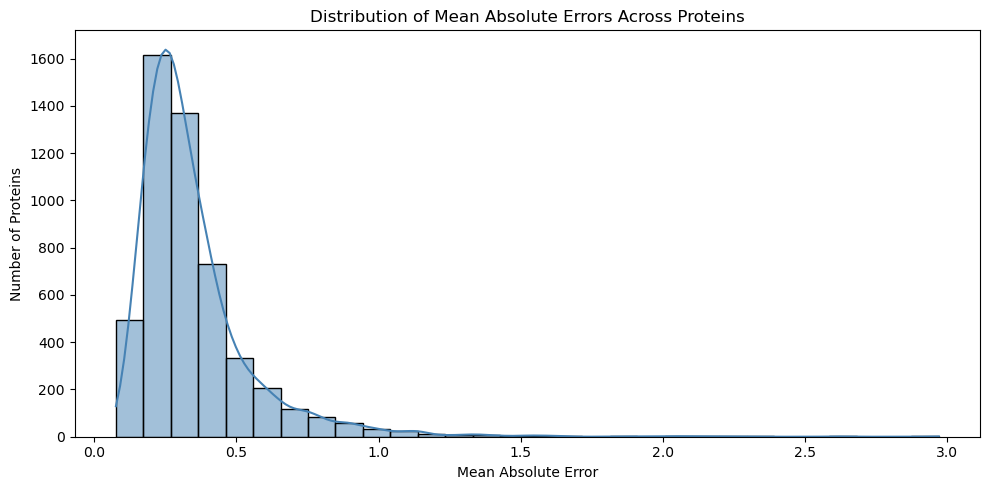

In [54]:
# 1. Compute median absolute error for each protein across samples
protein_means = combined_df.groupby("protein")["squared_error"].mean().reset_index()
protein_means.rename(columns={"squared_error": "mean_squared_error"}, inplace=True)

# 2. Plot the distribution
plt.figure(figsize=(10, 5))
sns.histplot(protein_means["mean_squared_error"], bins=30, kde=True, color="steelblue")

plt.title("Distribution of Mean Absolute Errors Across Proteins")
plt.xlabel("Mean Absolute Error")
plt.ylabel("Number of Proteins")
plt.tight_layout()
plt.show()

Proteins with mean_abs_error < 0.1: 16


c:\Users\hp\anaconda3\Lib\site-packages\seaborn\_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):


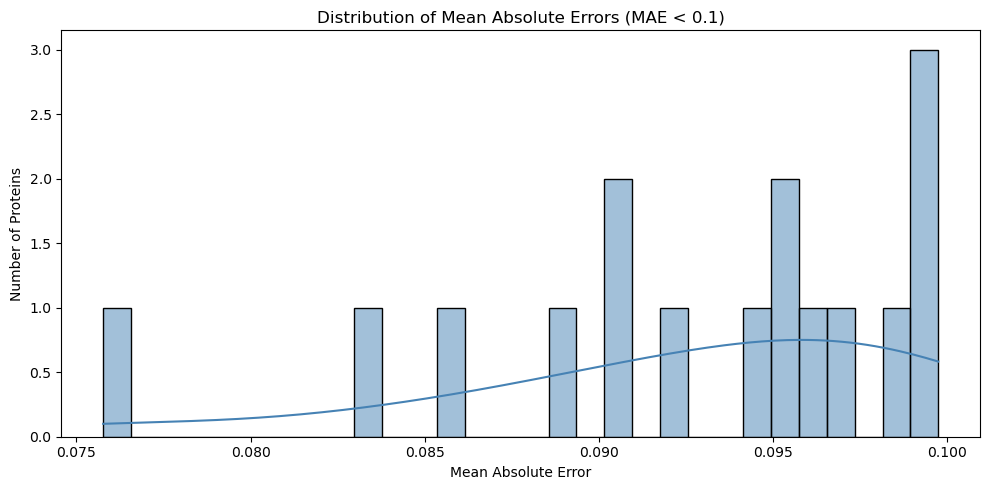

In [ ]:
# MAE < 0.1
threshold = 0.1
subset = protein_means.loc[protein_means["mean_squared_error"] < threshold, "mean_squared_error"]

print(f"Proteins with mean_squared_error < {threshold}: {subset.shape[0]}")

if subset.empty:
    print("No proteins below this threshold to plot.")
else:
    plt.figure(figsize=(10, 5))
    sns.histplot(subset, bins=30, kde=True, color="steelblue")
    plt.title("Distribution of Mean Squared Errors (MSE < 0.1)")
    plt.xlabel("Mean Squared Error")
    plt.ylabel("Number of Proteins")
    plt.tight_layout()
    plt.show()


Proteins with mean_abs_error < 0.2: 884


c:\Users\hp\anaconda3\Lib\site-packages\seaborn\_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):


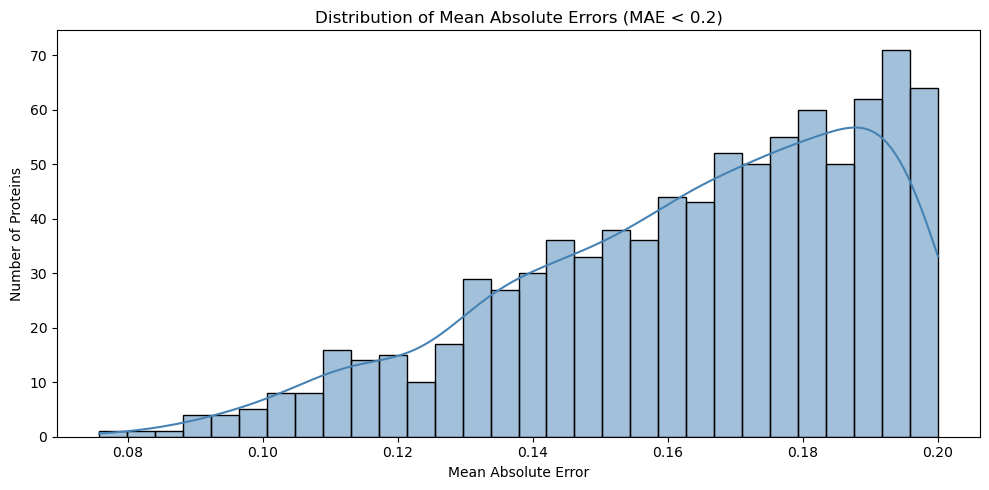

In [ ]:
# Cell: MAE < 0.2
threshold = 0.2
subset = protein_means.loc[protein_means["mean_squared_error"] < threshold, "mean_squared_error"]

print(f"Proteins with mean_squared_error < {threshold}: {subset.shape[0]}")

if subset.empty:
    print("No proteins below this threshold to plot.")
else:
    plt.figure(figsize=(10, 5))
    sns.histplot(subset, bins=30, kde=True, color="steelblue")
    plt.title("Distribution of Mean Squared Errors (MSE < 0.2)")
    plt.xlabel("Mean Squared Error")
    plt.ylabel("Number of Proteins")
    plt.tight_layout()
    plt.show()


Proteins with mean_squared_error < 0.3: 2643


c:\Users\hp\anaconda3\Lib\site-packages\seaborn\_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):


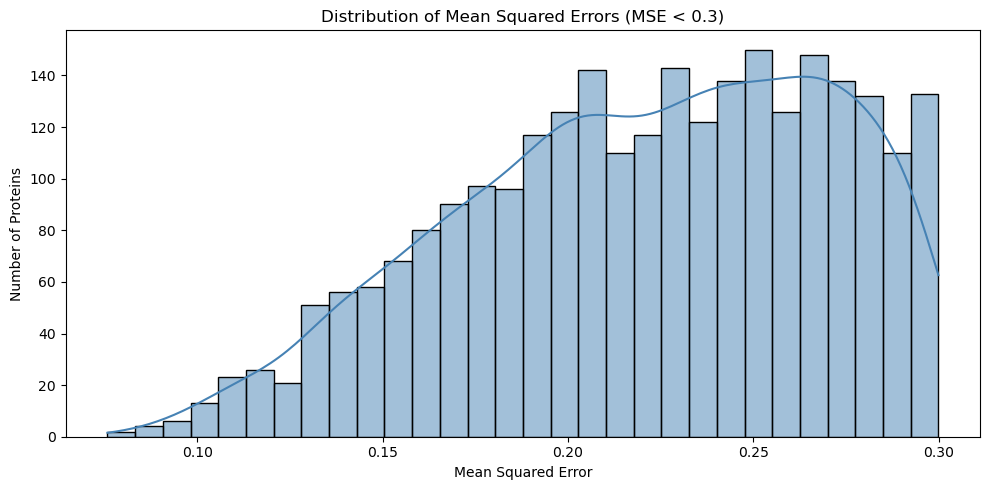

In [58]:
# Cell: MAE < 0.3
threshold = 0.3
subset = protein_means.loc[protein_means["mean_squared_error"] < threshold, "mean_squared_error"]

print(f"Proteins with mean_squared_error < {threshold}: {subset.shape[0]}")

if subset.empty:
    print("No proteins below this threshold to plot.")
else:
    plt.figure(figsize=(10, 5))
    sns.histplot(subset, bins=30, kde=True, color="steelblue")
    plt.title("Distribution of Mean Squared Errors (MSE < 0.3)")
    plt.xlabel("Mean Squared Error")
    plt.ylabel("Number of Proteins")
    plt.tight_layout()
    plt.show()


No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.


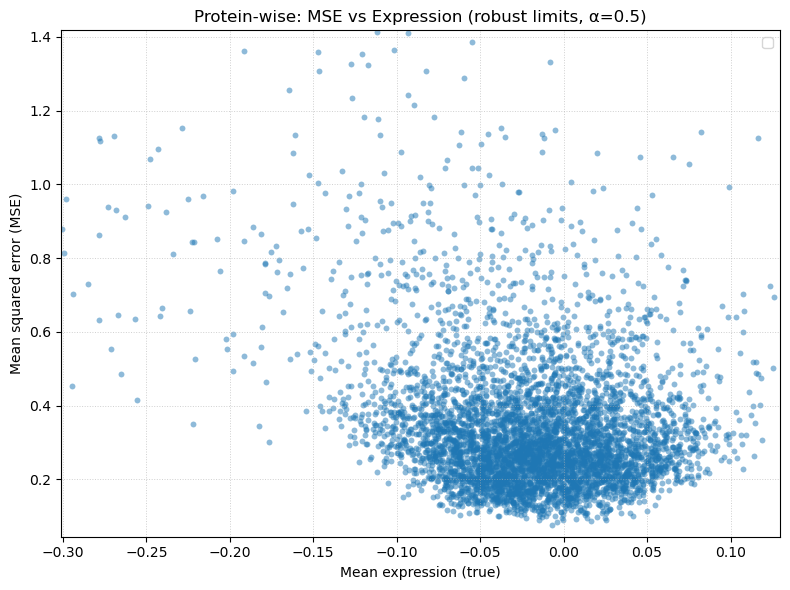

In [61]:
# MSE vs expression with robust limits and readable 1:1 line

# Recompute per-protein summary (safe if it already exists)
prot_perf = (
    combined_df.groupby('protein')
    .agg(expression=('true', 'mean'),
         mse=('squared_error', 'mean'),
         mae=('abs_error', 'mean'))
    .reset_index()
)

x = prot_perf['expression'].to_numpy()
y = prot_perf['mse'].to_numpy()

# Robust axis limits (clip to 0.5–99.5 percentiles and pad 5%)
x_lo, x_hi = np.nanpercentile(x, [0.5, 99.5])
y_lo, y_hi = np.nanpercentile(y, [0.5, 99.5])
x_pad = 0.05 * (x_hi - x_lo) if np.isfinite(x_hi - x_lo) else 1.0
y_pad = 0.05 * (y_hi - y_lo) if np.isfinite(y_hi - y_lo) else 1.0
xlim = (x_lo - x_pad, x_hi + x_pad)
ylim = (y_lo - y_pad, y_hi + y_pad)

plt.figure(figsize=(8, 6))
sns.scatterplot(
    data=prot_perf, x='expression', y='mse',
    s=18, alpha=0.5, linewidth=0, edgecolor=None
)


plt.xlim(*xlim)
plt.ylim(*ylim)
plt.xlabel('Mean expression (true)')
plt.ylabel('Mean squared error (MSE)')
plt.title('Protein-wise: MSE vs Expression (robust limits, α=0.5)')
plt.grid(True, linestyle=':', linewidth=0.7, alpha=0.6)
plt.legend()
plt.tight_layout()
plt.show()


In [ ]:
# Cell: MSE vs Expression (sorted by MAE)
import numpy as np

# Sort by MAE
pp_mae = prot_perf.sort_values('mae').reset_index(drop=True)

x = pp_mae['expression'].to_numpy()
y = pp_mae['mse'].to_numpy()

# Keep finite values for limits and 1:1 line
mask = np.isfinite(x) & np.isfinite(y)
x_f, y_f = x[mask], y[mask]
lo = float(min(x_f.min(), y_f.min())) if x_f.size and y_f.size else 0.0
hi = float(max(x_f.max(), y_f.max())) if x_f.size and y_f.size else 1.0

plt.figure(figsize=(8, 6))
sns.scatterplot(x=x, y=y, s=25, edgecolor='k')
plt.plot([lo, hi], [lo, hi], linestyle='--', linewidth=1, color='gray', label='y = x (1:1)')
plt.xlabel('Mean expression (true)')
plt.ylabel('Mean squared error (MSE)')
plt.title('Protein-wise: MSE vs Expression (sorted by MAE)')
plt.xlim(lo, hi)
plt.ylim(lo, hi)
plt.gca().set_aspect('equal', adjustable='box')
plt.legend()
plt.tight_layout()
plt.show()


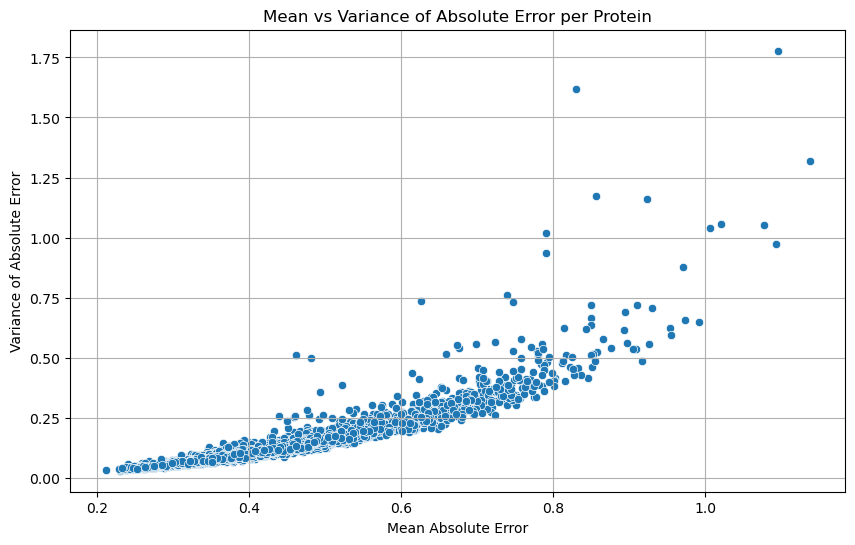

In [45]:
# Mean and variance per protein
protein_stats = combined_df.groupby('protein')['abs_error'].agg(['mean', 'var']).reset_index()

# Plot
plt.figure(figsize=(10, 6))
sns.scatterplot(data=protein_stats, x='mean', y='var')
plt.title("Mean vs Variance of Absolute Error per Protein")
plt.xlabel("Mean Absolute Error")
plt.ylabel("Variance of Absolute Error")
plt.grid(True)
plt.show()


#### mean error vs variance of true values

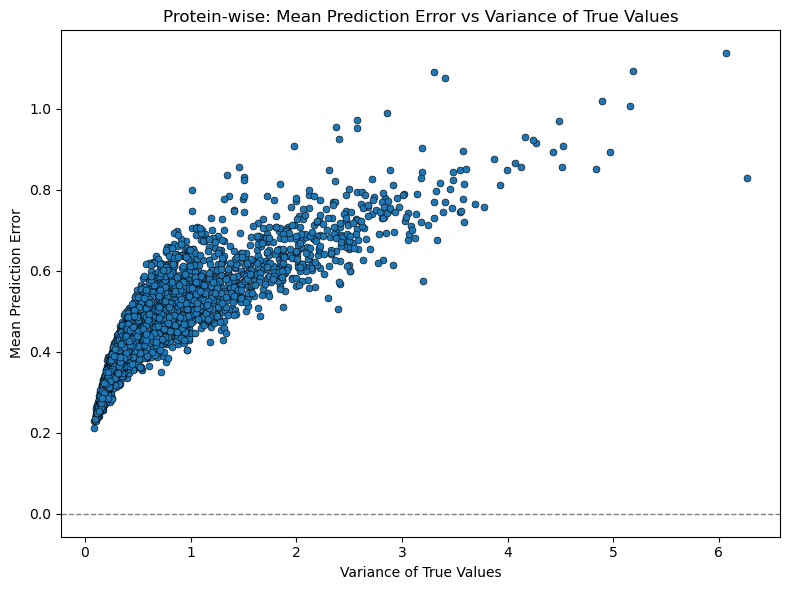

In [46]:
#Aggregate per protein 

prot_stats = (
    combined_df
    .groupby('protein')
    .agg(
        mean_error = ('abs_error', 'mean'),
        var_true   = ('true', 'var'),
    )
    .reset_index()
)

plt.figure(figsize=(8, 6))
sns.scatterplot(
    data=prot_stats,
    x='var_true',
    y='mean_error',
    s=25,
    edgecolor='k'
)
plt.axhline(0, color='gray', linestyle='--', linewidth=1)
plt.title('Protein‑wise: Mean Prediction Error vs Variance of True Values')
plt.xlabel('Variance of True Values')
plt.ylabel('Mean Prediction Error')
plt.tight_layout()
plt.show()

### Comparison with baseline

In [47]:
s = pd.read_csv("res_data/pe85.csv", dtype=str)["id"]   # Series
pe85 = s.tolist()                        # list

# Samples analysis


In [ ]:
protein_name = 'DYNLL1'
# Filter combined_df for that protein
protein_df = combined_df[combined_df['protein'] == protein_name]
# Sort SAMPLES by absolute error
protein_df_sorted = protein_df.sort_values(by='abs_error', ascending=True)
# Display
smallest_error = protein_df_sorted[protein_df_sorted["abs_error"]< 0.1]
smallest_error[['LOO sample', 'abs_error']]  

,LOO sample,abs_error
465082,HCC2218_BREAST,0.000168
465029,A549_LUNG,0.001852
464987,BT549_BREAST,0.001941
465174,KYM1_SOFT_TISSUE,0.003911
465273,UMUC3_URINARY_TRACT,0.003959
...,...,...
465150,HEC6_ENDOMETRIUM,0.093950
464953,KMRC20_KIDNEY,0.094580
465066,LOXIMVI_SKIN,0.096903
465023,LK2_LUNG,0.097010


In [ ]:
sample_error_summary = combined_df.groupby('LOO sample').agg(
    mean_abs_error=('abs_error', 'mean'),
    std_abs_error=('abs_error', 'std'),
    mean_squared_error=('squared_error', 'mean'),
    std_squared_error=('squared_error', 'std'),
    count=('LOO sample', 'count')
).sort_values(by='mean_abs_error', ascending=False)

sample_error_summary.head()

,mean_abs_error,std_abs_error,mean_squared_error,std_squared_error,count
LOO sample,,,,,
RCHACV_HAEMATOPOIETIC_AND_LYMPHOID_TISSUE,0.920625,0.610738,1.220479,1.455291,5113
MOLM13_HAEMATOPOIETIC_AND_LYMPHOID_TISSUE,0.767843,0.582728,0.929088,1.412112,5113
KNS81_CENTRAL_NERVOUS_SYSTEM,0.722669,0.540907,0.814773,1.251792,5113
NCIH1573_LUNG,0.699855,0.581263,0.827597,1.407798,5113
IM95_STOMACH,0.698584,0.537699,0.777084,2.054422,5113


c:\Users\hp\anaconda3\Lib\site-packages\seaborn\_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):


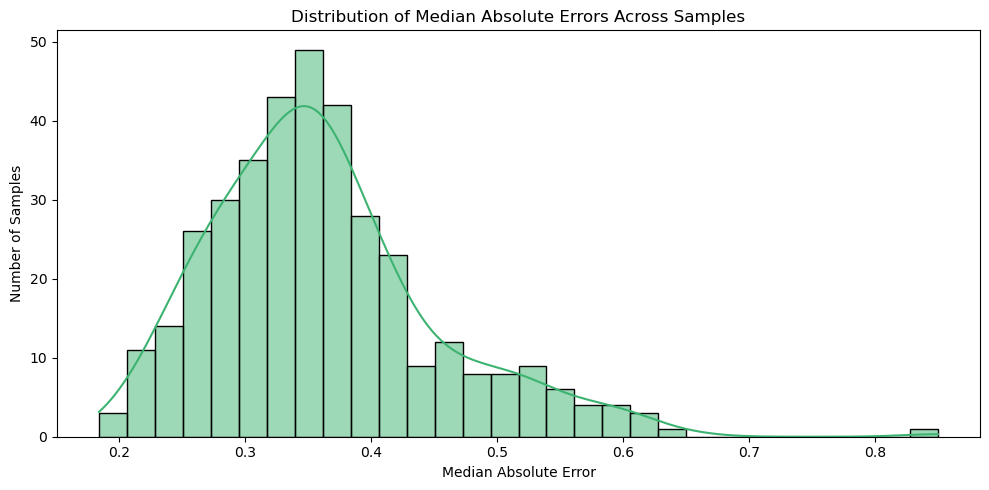

In [ ]:
# Compute median absolute error across proteins for each sample
sample_medians = combined_df.groupby("LOO sample")["abs_error"].median().reset_index()
sample_medians.rename(columns={"abs_error": "median_abs_error"}, inplace=True)

# Plot
plt.figure(figsize=(10, 5))
sns.histplot(sample_medians["median_abs_error"], bins=30, kde=True, color="mediumseagreen")

plt.title("Distribution of Median Absolute Errors Across Samples")
plt.xlabel("Median Absolute Error")
plt.ylabel("Number of Samples")
plt.tight_layout()
plt.show()


c:\Users\hp\anaconda3\Lib\site-packages\seaborn\_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):


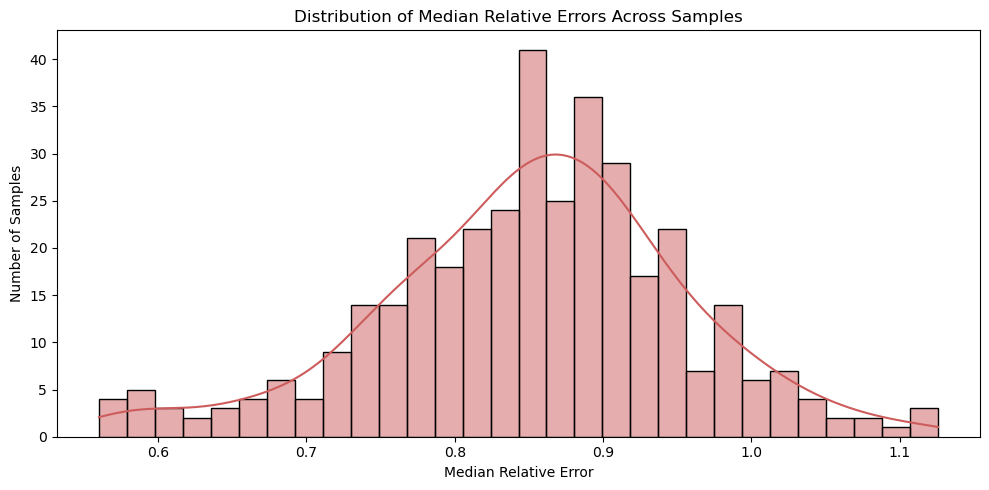

In [ ]:
# Compute median relative error across proteins for each sample
sample_medians_rel = combined_df.groupby("LOO sample")["rel_error"].median().reset_index()
sample_medians_rel.rename(columns={"rel_error": "median_rel_error"}, inplace=True)

# Plot
plt.figure(figsize=(10, 5))
sns.histplot(sample_medians_rel["median_rel_error"], bins=30, kde=True, color="indianred")

plt.title("Distribution of Median Relative Errors Across Samples")
plt.xlabel("Median Relative Error")
plt.ylabel("Number of Samples")
plt.tight_layout()
plt.show()


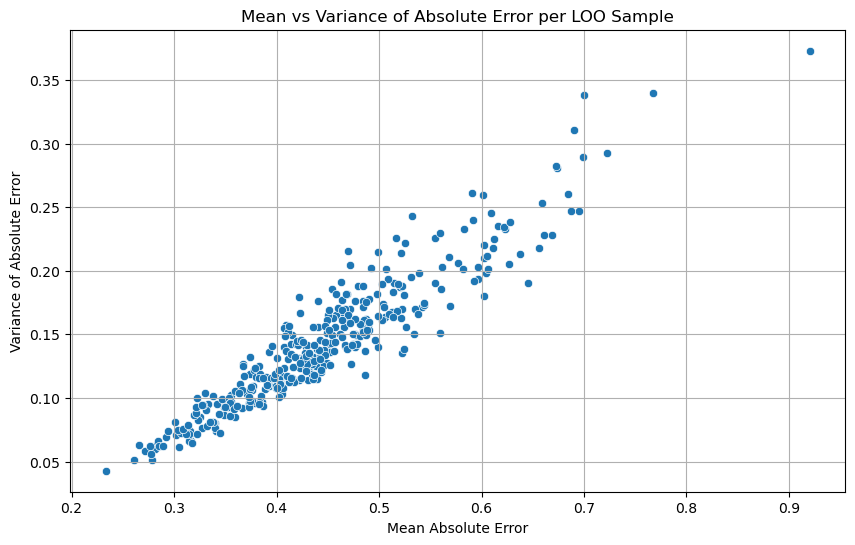

In [ ]:
sample_stats = combined_df.groupby('LOO sample')['abs_error'].agg(['mean', 'var']).reset_index()

# Plot
plt.figure(figsize=(10, 6))
sns.scatterplot(data=sample_stats, x='mean', y='var')
plt.title("Mean vs Variance of Absolute Error per LOO Sample")
plt.xlabel("Mean Absolute Error")
plt.ylabel("Variance of Absolute Error")
plt.grid(True)
plt.show()


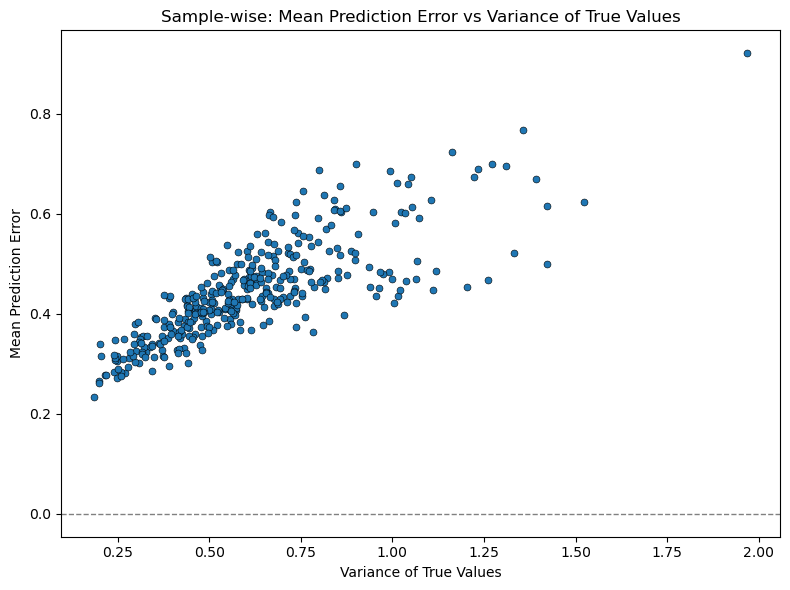

In [ ]:
# Aggregate per LOO sample
sample_stats = (
    combined_df
    .groupby('LOO sample')
    .agg(
        mean_error = ('abs_error', 'mean'),
        var_true    = ('true', 'var'),
    )
    .reset_index()
)

plt.figure(figsize=(8, 6))
sns.scatterplot(
    data=sample_stats,
    x='var_true',
    y='mean_error',
    s=25,
    edgecolor='k'
)
plt.axhline(0, color='gray', linestyle='--', linewidth=1)
plt.title('Sample‑wise: Mean Prediction Error vs Variance of True Values')
plt.xlabel('Variance of True Values')
plt.ylabel('Mean Prediction Error')
plt.tight_layout()
plt.show()

display the samples with less than 0.1 error

In [ ]:
def get_less_than01(protein_name, df, error_col='abs_error', sample_col='LOO sample'):
    protein_df = df[df['protein'] == protein_name]
    sorted_df = protein_df.sort_values(by=error_col, ascending=True)
    return sorted_df[[sample_col, error_col]].query(f"{error_col} < 0.1")

small = get_less_than01('DYNLL1', combined_df)
small


,LOO sample,abs_error
465082,HCC2218_BREAST,0.000168
465029,A549_LUNG,0.001852
464987,BT549_BREAST,0.001941
465174,KYM1_SOFT_TISSUE,0.003911
465273,UMUC3_URINARY_TRACT,0.003959
...,...,...
465150,HEC6_ENDOMETRIUM,0.093950
464953,KMRC20_KIDNEY,0.094580
465066,LOXIMVI_SKIN,0.096903
465023,LK2_LUNG,0.097010


In [ ]:
# Extract the tissue type from the LOO sample
small['tissue'] = small['LOO sample'].str.extract(r'_([A-Z]+)$')

# Count the occurrences of each tissue
tissue_counts = small['tissue'].value_counts()

print(tissue_counts)


tissue
LUNG           20
SKIN           16
INTESTINE      11
LIVER           9
BREAST          8
TRACT           7
OESOPHAGUS      6
SYSTEM          6
ENDOMETRIUM     5
OVARY           5
STOMACH         5
TISSUE          4
KIDNEY          4
PANCREAS        3
PROSTATE        2
PLEURA          2
BONE            1
THYROID         1
Name: count, dtype: int64


Check between the best proteins for absolute error if the samples correspond

In [ ]:
# Get the top 10 proteins with the lowest median absolute error
top_10_proteins = protein_error_summary.head(10).index.tolist()

# Dictionary to store results
low_error_samples_by_protein = {}

# Loop through top 10 proteins and apply your function
for prot in top_10_proteins:
    low_error_samples_by_protein[prot] = get_less_than01(prot, combined_df)

# see low-error samples for the first protein
low_error_samples_by_protein[top_10_proteins[0]]
summary = {
    prot: len(df)
    for prot, df in low_error_samples_by_protein.items()
}

summary_df = pd.DataFrame.from_dict(summary, orient='index', columns=['low_error_count'])
summary_df


,low_error_count
IGF2BP1,45
BASP1,23
MAGEA4,50
GDA,50
MAP1B,41
LAD1,44
ST14,32
LCP1,40
ESRP1,42
SERPINB5,31


In [ ]:
low_error_sample_sets = {
    prot: set(get_less_than01(prot, combined_df)['LOO sample'])
    for prot in top_10_proteins
}

# Find intersection: samples that are low-error across *all* top 10 proteins
common_low_error_samples = set.union(*low_error_sample_sets.values())

print(f"Number of samples with abs_error < 0.1 across ALL top 10 proteins: {len(common_low_error_samples)}")
print("Common samples:", common_low_error_samples)

Number of samples with abs_error < 0.1 across ALL top 10 proteins: 239
Common samples: {'COLO741_SKIN', 'CAL33_UPPER_AERODIGESTIVE_TRACT', 'RVH421_SKIN', 'HCC44_LUNG', 'KASUMI1_HAEMATOPOIETIC_AND_LYMPHOID_TISSUE', 'LS180_LARGE_INTESTINE', 'SNU449_LIVER', 'SU8686_PANCREAS', 'HS294T_SKIN', 'BICR6_UPPER_AERODIGESTIVE_TRACT', 'VMRCRCW_KIDNEY', 'K562_HAEMATOPOIETIC_AND_LYMPHOID_TISSUE', 'IALM_LUNG', 'MOLM13_HAEMATOPOIETIC_AND_LYMPHOID_TISSUE', 'HT115_LARGE_INTESTINE', 'NCIH460_LUNG', 'HUH7_LIVER', 'HEP3B217_LIVER', 'IGR1_SKIN', 'RCHACV_HAEMATOPOIETIC_AND_LYMPHOID_TISSUE', 'G401_SOFT_TISSUE', 'SW480_LARGE_INTESTINE', 'COLO320_LARGE_INTESTINE', 'SUDHL6_HAEMATOPOIETIC_AND_LYMPHOID_TISSUE', 'NCIH1944_LUNG', 'HCC1954_BREAST', 'HCC1833_LUNG', 'PC3_PROSTATE', 'A704_KIDNEY', 'CMK_HAEMATOPOIETIC_AND_LYMPHOID_TISSUE', 'SNU61_LARGE_INTESTINE', 'THP1_HAEMATOPOIETIC_AND_LYMPHOID_TISSUE', 'SKNMC_BONE', 'HEL_HAEMATOPOIETIC_AND_LYMPHOID_TISSUE', 'KASUMI2_HAEMATOPOIETIC_AND_LYMPHOID_TISSUE', 'SKMEL5_SKIN', 

How many times a tissue appears in the top predicted proteins

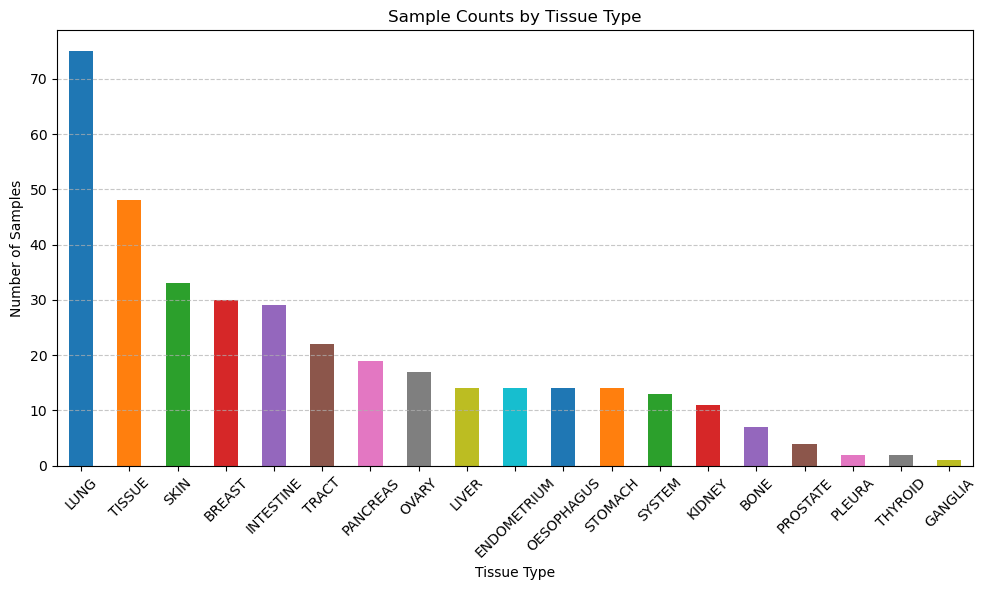

In [ ]:
protein_df_sorted['tissue'] = protein_df_sorted['LOO sample'].str.extract(r'_([A-Z]+)$')

# Count occurrences of each tissue type
tissue_counts = protein_df_sorted['tissue'].value_counts()

# Assign a different color to each tissue
colors = plt.cm.tab10.colors  # Use a colormap with distinct colors
color_list = colors[:len(tissue_counts)]  # Adjust if >10 tissues

# Plot with different colors
plt.figure(figsize=(10, 6))
tissue_counts.plot(kind='bar', color=color_list)
plt.title('Sample Counts by Tissue Type')
plt.xlabel('Tissue Type')
plt.ylabel('Number of Samples')
plt.xticks(rotation=45)
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

In [ ]:
# Convert the union of sets to a list before using it as index
all_samples = list(set.union(*low_error_sample_sets.values()))

# Create the sample matrix with proper indexing
sample_matrix = pd.DataFrame(index=all_samples)

# Populate the matrix with binary indicators
for prot, sample_set in low_error_sample_sets.items():
    sample_matrix[prot] = sample_matrix.index.isin(sample_set).astype(int)

# Count in how many proteins each sample appears
sample_matrix['num_proteins'] = sample_matrix.sum(axis=1)

# Sort to find the most consistent low-error samples
sample_matrix_sorted = sample_matrix.sort_values(by='num_proteins', ascending=False)

# Step 1: Reset index to get sample names as a column
sample_matrix_reset = sample_matrix_sorted.reset_index().rename(columns={'index': 'sample'})

# Step 2: Extract tissue type from sample names (split by last underscore)
sample_matrix_reset['tissue'] = sample_matrix_reset['sample'].apply(lambda x: x.split('_')[-1])

# Step 3: Group by tissue and sum across all protein columns
tissue_summary = sample_matrix_reset.groupby('tissue').sum(numeric_only=True)

# Optional: Sort by number of appearances across proteins
tissue_summary = tissue_summary.sort_values(by='num_proteins', ascending=False)

tissue_summary.head(10)


,IGF2BP1,BASP1,MAGEA4,GDA,MAP1B,LAD1,ST14,LCP1,ESRP1,SERPINB5,num_proteins
tissue,,,,,,,,,,,
LUNG,9,4,11,8,9,10,3,7,7,6,74
TISSUE,4,2,6,5,6,7,4,3,9,7,53
SKIN,4,4,5,7,7,6,3,0,3,3,42
INTESTINE,6,5,3,3,4,2,3,9,3,1,39
BREAST,5,2,4,4,2,4,4,2,2,3,32
TRACT,3,1,2,5,1,0,3,5,3,2,25
LIVER,3,0,4,3,3,1,1,3,0,3,21
PANCREAS,2,2,4,3,2,2,1,1,3,0,20
SYSTEM,3,0,1,2,1,3,3,2,0,0,15


# MAE vs Prot- Encoding Gene correlations

In [ ]:
corrs

,pearson,spearman,kendall
A2M,0.373828,0.230195,0.157938
AAAS,0.033262,0.054040,0.037045
AACS,0.475468,0.446383,0.309187
AAGAB,0.345481,0.402540,0.279094
AAK1,0.623951,0.585448,0.414043
...,...,...,...
ZWINT,0.287495,0.285369,0.193985
ZYG11B,0.327869,0.335152,0.227918
ZYX,0.685739,0.657462,0.478076
ZZEF1,0.343196,0.383925,0.260961


In [ ]:
sorted(protein_error_summary.index)

['A2M',
 'AAAS',
 'AACS',
 'AAGAB',
 'AAK1',
 'AAMDC',
 'AAMP',
 'AAR2',
 'AARS',
 'AARS2',
 'AARSD1',
 'AASDHPPT',
 'AASS',
 'AATF',
 'ABCB10',
 'ABCB6',
 'ABCB7',
 'ABCB8',
 'ABCC1',
 'ABCC4',
 'ABCD1',
 'ABCD3',
 'ABCE1',
 'ABCF1',
 'ABCF2',
 'ABCF3',
 'ABHD10',
 'ABHD11',
 'ABHD12',
 'ABHD14B',
 'ABHD16A',
 'ABI1',
 'ABI2',
 'ABLIM1',
 'ABT1',
 'ACAA1',
 'ACAA2',
 'ACACA',
 'ACAD10',
 'ACAD8',
 'ACAD9',
 'ACADM',
 'ACADS',
 'ACADSB',
 'ACADVL',
 'ACAP2',
 'ACAT1',
 'ACAT2',
 'ACBD3',
 'ACBD5',
 'ACBD6',
 'ACIN1',
 'ACLY',
 'ACO1',
 'ACO2',
 'ACOT13',
 'ACOT2',
 'ACOT7',
 'ACOT8',
 'ACOT9',
 'ACOX1',
 'ACP1',
 'ACP2',
 'ACP6',
 'ACSF2',
 'ACSF3',
 'ACSL1',
 'ACSL3',
 'ACSL4',
 'ACSL5',
 'ACSS2',
 'ACTA2',
 'ACTB',
 'ACTL6A',
 'ACTL8',
 'ACTN1',
 'ACTN4',
 'ACTR10',
 'ACTR1A',
 'ACTR2',
 'ACTR3',
 'ACTR5',
 'ACY1',
 'ACYP1',
 'ACYP2',
 'ADA',
 'ADAM10',
 'ADAM15',
 'ADAM17',
 'ADAM9',
 'ADAR',
 'ADCK3',
 'ADCK4',
 'ADD1',
 'ADD3',
 'ADH5',
 'ADI1',
 'ADIRF',
 'ADK',
 'ADNP',
 'ADO',


In [ ]:
corrs = corrs.reindex(protein_error_summary.index)
corrs

,pearson,spearman,kendall
protein,,,
IGF2BP1,0.910633,0.831373,0.638656
BASP1,0.907582,0.882568,0.685089
MAGEA4,0.899245,0.470281,0.335682
GDA,0.861059,0.680194,0.501851
MAP1B,0.892199,0.894819,0.706390
...,...,...,...
MRPS30,0.029631,0.030751,0.020991
OTUB1,0.372115,0.394512,0.272672
CNOT11,0.192063,0.179745,0.122058


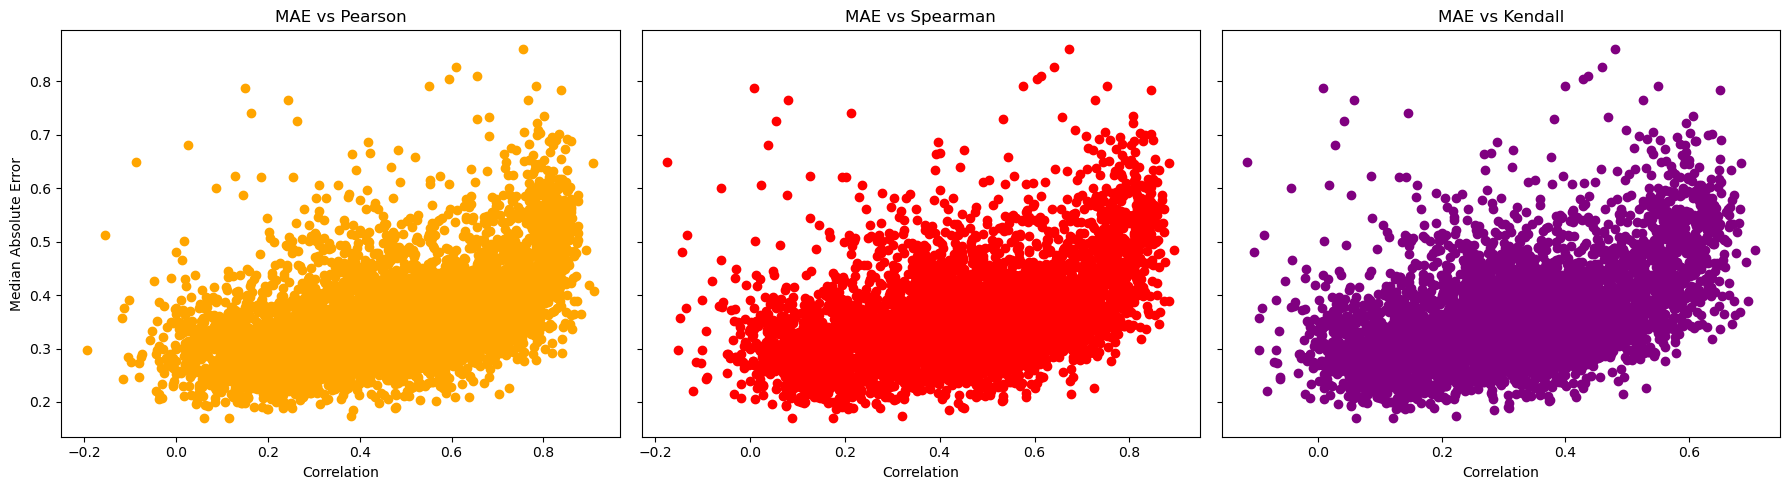

In [ ]:

mae = protein_error_summary['median_abs_error']

# Define custom colors for each correlation type
colors = ['orange', 'red', 'purple']  # Feel free to change these

# Create subplots: 1 row, 3 columns
fig, axes = plt.subplots(1, 3, figsize=(18, 5), sharey=True)

# Plot each correlation type separately
for ax, col, color in zip(axes, corrs.columns, colors):
    ax.scatter(corrs[col], mae, color=color)
    ax.set_title(f'MAE vs {col.capitalize()}')
    ax.set_xlabel('Correlation')
    ax.grid(False)

# Common Y label
axes[0].set_ylabel('Median Absolute Error')

plt.tight_layout()
plt.show()



# Cluster-Wise analysis

In [ ]:
clusters = pd.read_csv("res_data/protein_clusters_k3.csv")

In [ ]:
clusters

,Protein,Cluster
0,A2M,3
1,AAAS,3
2,AACS,3
3,AAGAB,1
4,AAK1,2
...,...,...
5108,ZRANB2,1
5109,ZW10,3
5110,ZWILCH,1
5111,ZYX,3


Distributions

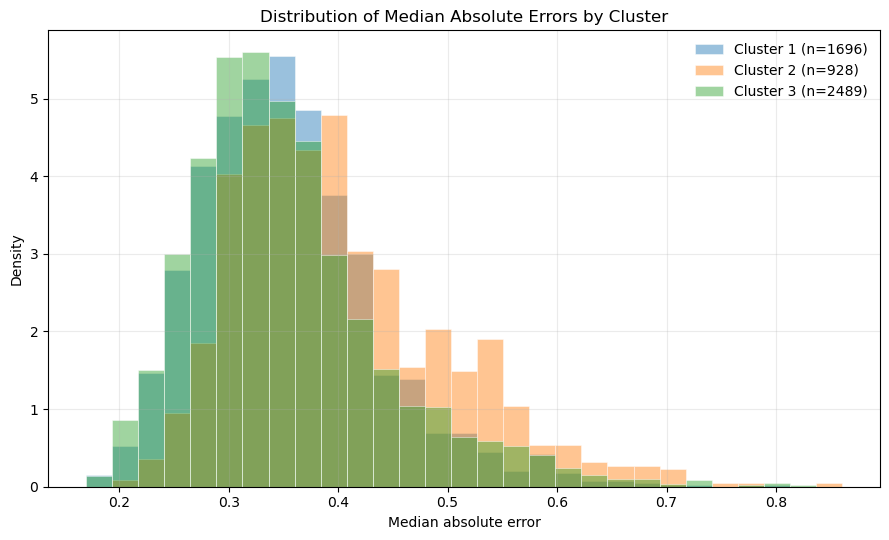

In [ ]:

# --- Prep: merge error + cluster labels ---
err = protein_error_summary[['median_abs_error']].rename_axis('Protein').reset_index()
df = err.merge(clusters, on='Protein', how='inner')

# Consistent bins across clusters
bins = np.linspace(df['median_abs_error'].min(), df['median_abs_error'].max(), 30)

# Pick distinct colors for the three clusters
palette = {1: "#1f77b4", 2: "#ff7f0e", 3: "#2ca02c"}  # blue, orange, green

plt.figure(figsize=(9, 5.5))
for c in sorted(df['Cluster'].unique()):
    vals = df.loc[df['Cluster'] == c, 'median_abs_error']
    plt.hist(
        vals, bins=bins, density=True, alpha=0.45,
        label=f"Cluster {c} (n={len(vals)})",
        color=palette.get(c, None), edgecolor="white", linewidth=0.7
    )

plt.title("Distribution of Median Absolute Errors by Cluster")
plt.xlabel("Median absolute error")
plt.ylabel("Density")
plt.legend(frameon=False)
plt.grid(alpha=0.25)
plt.tight_layout()
plt.show()


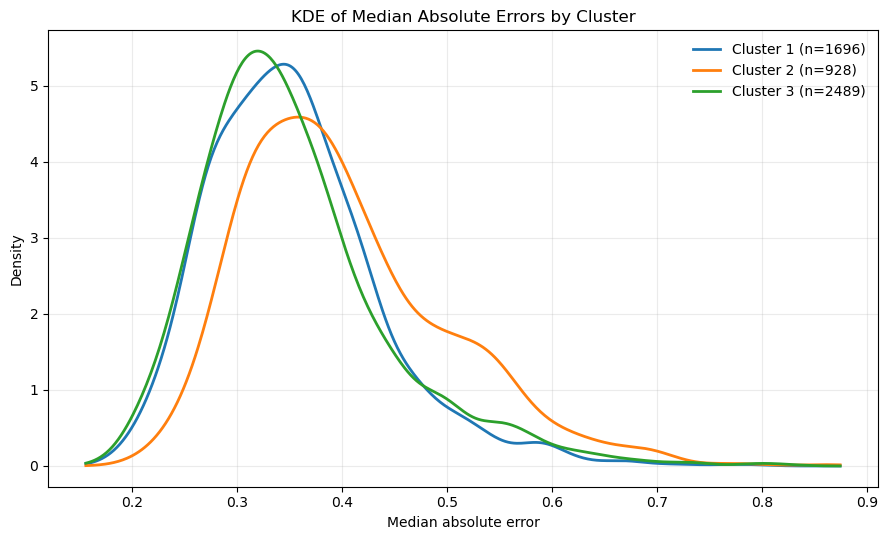

In [ ]:

from scipy.stats import gaussian_kde

# err + clusters already merged into df as in your snippet
# df has columns: Protein, median_abs_error, Cluster
palette = {1: "#1f77b4", 2: "#ff7f0e", 3: "#2ca02c"}

# Common x-axis over the full range (with a small padding)
xmin, xmax = df['median_abs_error'].min(), df['median_abs_error'].max()
xr = np.linspace(xmin - 0.02*(xmax - xmin), xmax + 0.02*(xmax - xmin), 512)

plt.figure(figsize=(9, 5.5))
for c in sorted(df['Cluster'].unique()):
    vals = df.loc[df['Cluster'] == c, 'median_abs_error'].to_numpy()

    if len(vals) < 2:
        # KDE needs >=2 points; fall back to a thin vertical line at the value
        if len(vals) == 1:
            plt.axvline(vals[0], ymax=0.12, color=palette[c], lw=2, label=f"Cluster {c} (n=1)")
        continue

    kde = gaussian_kde(vals)  # you can tune bandwidth via bw_method=0.3, etc.
    y = kde(xr)
    plt.plot(xr, y, lw=2, color=palette[c], label=f"Cluster {c} (n={len(vals)})")
    # Optional soft shading (comment out if you truly want lines only)
    # plt.fill_between(xr, y, alpha=0.12, color=palette[c])

plt.title("KDE of Median Absolute Errors by Cluster")
plt.xlabel("Median absolute error")
plt.ylabel("Density")
plt.legend(frameon=False)
plt.grid(alpha=0.25)
plt.tight_layout()
plt.show()


Scatterplot

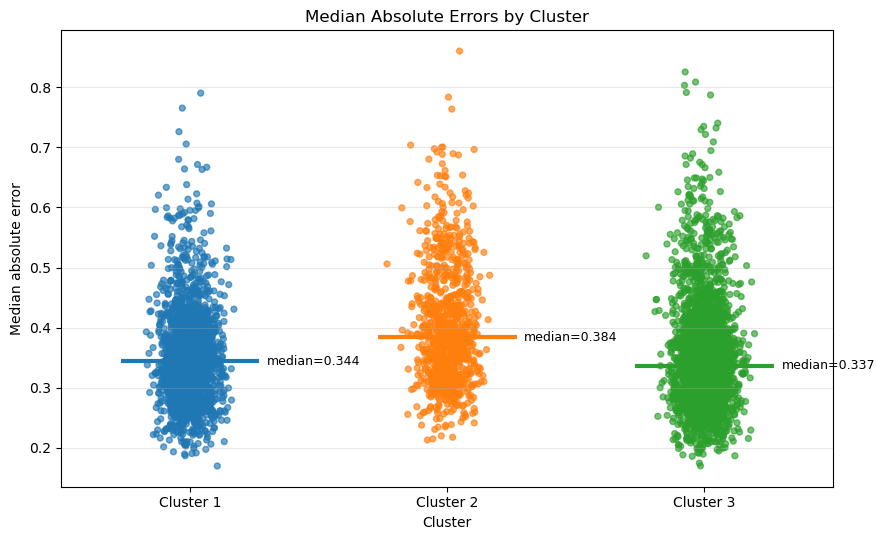

In [ ]:

rng = np.random.default_rng(0)  # reproducible jitter
x = df['Cluster'].astype(int).to_numpy()
y = df['median_abs_error'].to_numpy()

# Small horizontal jitter so points don’t overlap
x_jittered = x + rng.normal(0, 0.06, size=len(x))
colors = df['Cluster'].map(palette).to_numpy()

plt.figure(figsize=(9, 5.5))
plt.scatter(x_jittered, y, s=18, alpha=0.65, c=colors)

# Add one horizontal median line per cluster for visual comparison
for c in sorted(df['Cluster'].unique()):
    y_c = df.loc[df['Cluster'] == c, 'median_abs_error']
    plt.hlines(y_c.median(), c - 0.27, c + 0.27, colors=palette[c], linewidth=3)
    plt.text(c + 0.3, y_c.median(), f"median={y_c.median():.3f}", fontsize=9, va="center")

plt.xticks([1, 2, 3], ["Cluster 1", "Cluster 2", "Cluster 3"])
plt.xlim(0.5, 3.5)
plt.title("Median Absolute Errors by Cluster") #scattered by jitter
plt.xlabel("Cluster")
plt.ylabel("Median absolute error")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()
